# AutoHetero results on the RTX 3050 Laptop GPU

A guided read of the numbers measured on this laptop (2026-10-26). Every chart is built from the files the
evaluation scripts wrote — `bench/data/`, `bench/results/`, `eval/out/` — so rerunning the experiments and then
this notebook updates everything except the prose notes, which describe this run.

**Words used throughout**

| term | meaning |
|---|---|
| **CPU / GPU** | run the whole call on one device (the "always-CPU" / "always-GPU" strategies) |
| **Hybrid** | split one call's batch between CPU and GPU so both finish together |
| **AutoHetero** | the library deciding per call between CPU, GPU and Hybrid, and switching mid-call if it sees a slowdown |
| **oracle** | the fastest strategy actually measured for that workload: the best any dispatcher could do |
| **speedup vs X** | X's time ÷ AutoHetero's time. Above 1 = AutoHetero faster |
| **gap to oracle** | how much slower AutoHetero was than the oracle (0.4 = 40% slower) |
| **regret** | for a predictor: extra time paid when it picks the wrong device (a wrong pick between two near-equal devices costs little) |

Run from the repository root or from `eval/`, with the project's environment
(`pip install -e ".[dev]" pandas jupyter`).

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "eval").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from eval import common  # the project's colours and axis style

OUT = ROOT / "eval" / "out"
newest = lambda folder: sorted((ROOT / folder).glob("*.csv"), key=lambda p: p.stat().st_mtime)
dataset = newest("bench/data")[-1]
results = [p for p in newest("bench/results") if "all-conditions" not in p.name]  # each run once, not the merged copy
raw = pd.concat([pd.read_csv(p) for p in results])

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9})
C = common.COLORS
print("dataset:", dataset.name)
print("results:", [p.name for p in results])

dataset: LAPTOP-9KPB5IBV-20261026-002239.csv
results: ['LAPTOP-9KPB5IBV-20261026-003745.csv', 'LAPTOP-9KPB5IBV-20261026-005604.csv', 'LAPTOP-9KPB5IBV-20261026-014830.csv']


## 1. The machine and its one-off calibration

On first use AutoHetero spends ~30 s measuring the machine. These numbers are the "physics" every later
decision rests on: moving data to the GPU and back costs time, and so does starting work on it.

In [2]:
cal = json.loads(next((Path.home() / ".cache" / "autohetero").glob("*/calibration.json")).read_text())
info = json.loads(dataset.with_suffix(".json").read_text())
pd.DataFrame({
    "value": [info["gpu"], info["cpu"], info["driver"], info["torch"],
              f'{cal["h2d_bytes_per_s"] / 1e9:.2f} GB/s', f'{cal["d2h_bytes_per_s"] / 1e9:.2f} GB/s',
              f'{cal["launch_seconds"] * 1e6:.0f} µs', f'{cal["thread_seconds"] * 1e3:.2f} ms',
              f'{cal["concat_bytes_per_s"] / 1e9:.2f} GB/s', f'{cal["seconds"]} s'],
    "what it means": ["", "", "NVIDIA driver", "PyTorch build",
                      "copying inputs host → GPU", "copying results GPU → host (half as fast)",
                      "fixed cost of starting any GPU work", "cost of the extra thread Hybrid needs",
                      "joining Hybrid's two halves back together", "how long calibration took"],
}, index=["GPU", "CPU", "driver", "torch", "host→GPU", "GPU→host", "GPU launch", "thread start",
          "concatenate", "calibration time"])

,value,what it means
GPU,NVIDIA GeForce RTX 3050 Laptop GPU,
CPU,"AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD",
driver,617.14,NVIDIA driver
torch,2.11.0+cu128,PyTorch build
host→GPU,6.38 GB/s,copying inputs host → GPU
GPU→host,3.39 GB/s,copying results GPU → host (half as fast)
GPU launch,65 µs,fixed cost of starting any GPU work
thread start,0.70 ms,cost of the extra thread Hybrid needs
concatenate,8.18 GB/s,joining Hybrid's two halves back together
calibration time,32.6 s,how long calibration took


**Reading it:** a 100 MB image batch costs ~16 ms to send and ~30 ms to bring back before the GPU does
any work. So the GPU only pays off once the compute it saves is bigger than that round trip — which is what
the crossover in the next section measures.

## 2. Crossover: from what input size is the GPU faster?

`bench/collect.py` timed every built-in op at growing sizes on both devices (5 runs each, median shown).
Below 1× the CPU wins; above 1× the GPU wins. The point where a line crosses 1× is the crossover.

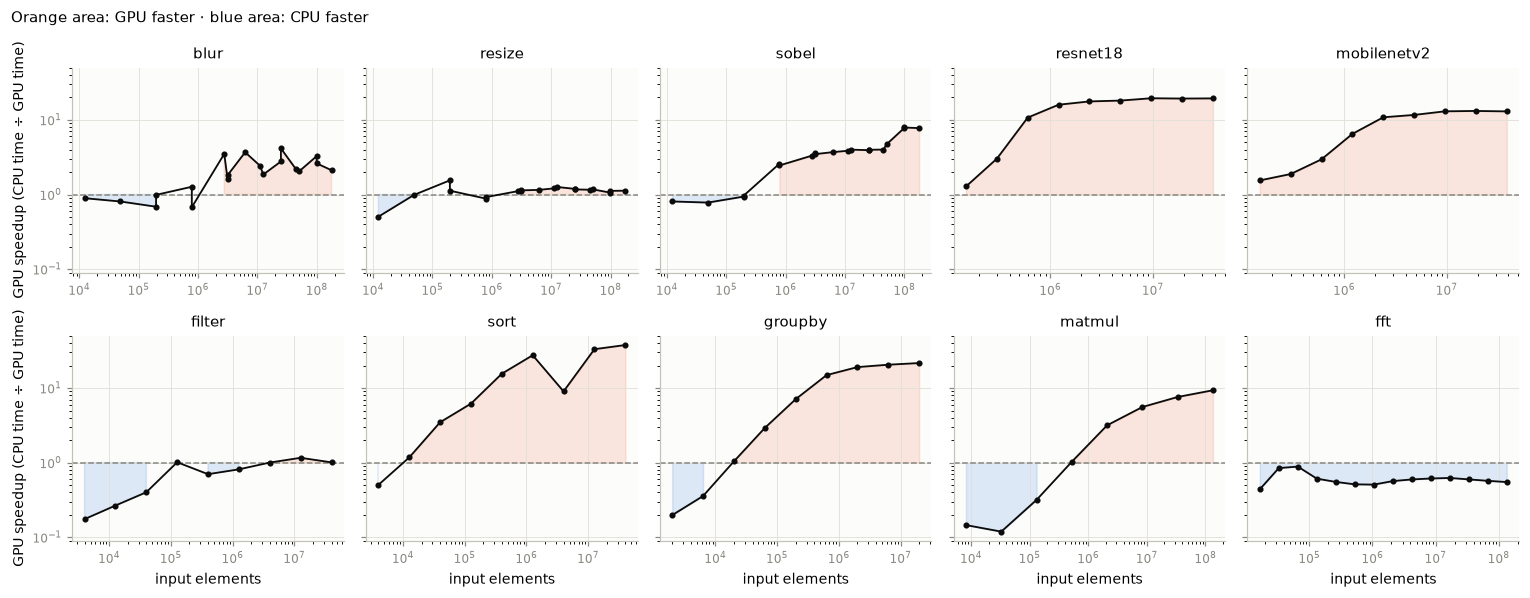

In [3]:
d = pd.read_csv(dataset)
med = d.groupby(["op", "size", "device"]).agg(elements=("elements", "first"), seconds=("seconds", "median")).reset_index()
wide = med.pivot_table(index=["op", "size", "elements"], columns="device", values="seconds").dropna().reset_index()
wide["gpu_speedup"] = wide["cpu"] / wide["gpu"]

ops = list(dict.fromkeys(d["op"]))
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5), sharey=True)
for ax, op in zip(axes.flat, ops):
    w = wide[wide["op"] == op].sort_values("elements")
    common.style(ax)
    ax.axhline(1, color=common.MUTED, lw=1, ls="--")
    ax.fill_between(w["elements"], 1, w["gpu_speedup"], where=w["gpu_speedup"] >= 1, color=C["gpu"], alpha=.15)
    ax.fill_between(w["elements"], 1, w["gpu_speedup"], where=w["gpu_speedup"] < 1, color=C["cpu"], alpha=.15)
    ax.plot(w["elements"], w["gpu_speedup"], "o-", ms=3, color=common.INK, lw=1.2)
    ax.set(xscale="log", yscale="log", title=op)
for ax in axes[1]: ax.set_xlabel("input elements")
for ax in axes[:, 0]: ax.set_ylabel("GPU speedup (CPU time ÷ GPU time)")
fig.suptitle("Orange area: GPU faster · blue area: CPU faster", x=0.01, ha="left", fontsize=10)
fig.tight_layout()

In [4]:
pd.read_csv(OUT / "crossover.csv").set_index("op")

,sizes_on_both,cpu_faster_up_to_elements,gpu_faster_from_elements,gpu_speedup_min,gpu_speedup_max
op,,,,,
blur,19,7.864e+05,786432.0,0.676,4.150
resize,19,7.864e+05,196608.0,0.504,1.550
sobel,19,1.966e+05,786432.0,0.780,7.910
resnet18,9,NaN,150528.0,1.280,19.500
mobilenetv2,9,NaN,150528.0,1.550,13.200
filter,9,1.265e+06,126492.0,0.175,1.160
sort,9,4.000e+03,12648.0,0.503,37.700
groupby,9,6.324e+03,20000.0,0.198,21.600
matmul,8,1.311e+05,524288.0,0.119,9.340


**Reading it:**
- **Neural networks (resnet18, mobilenetv2)** — GPU wins at every size, up to ~20× at large batches. Easy decision.
- **sort and groupby** — CPU wins only on tiny inputs; past ~10–20 k elements the GPU wins by up to 38× / 22×.
- **blur, sobel, matmul** — a clear crossover: CPU for small inputs, GPU (4–9×) for large ones.
- **resize and filter** — little arithmetic per byte moved, so the two devices stay within ~1.5× of each
  other and the winner flips with noise. Any pick is cheap here.
- **fft** — the CPU wins at every size measured (GPU 0.44–0.89×): the transfer cost is never repaid on this card.

So "always use the GPU" is wrong for fft and small inputs, and that gap is what AutoHetero is supposed to exploit.

## 3. RQ1 — can a small learned model predict the faster device?

A random forest (and a single decision tree, for comparison) predicts each device's time from the op, input
size and current load; the predicted-faster device is the pick. Four ways of testing it, from easiest to hardest:

| evaluation | trained on | tested on |
|---|---|---|
| holdout 80/20 | 80% of sizes | the other 20% |
| 5-fold | 4/5 of sizes, 5 times | the remaining 1/5 each time |
| leave-one-op-out | 9 ops | the 10th, never seen — the "new kind of workload" case |
| calibration → benchmark | the 30 s calibration only | the full benchmark dataset — what really happens on a new machine |

The design target is ≥ 90% accuracy (a hypothesis, not a requirement).

In [5]:
rq1 = pd.read_csv(OUT / "rq1.csv")
rq1.style.format({"accuracy": "{:.1%}", "regret": "{:.1%}", "time_error": "{:.1%}", "accuracy_std": "± {:.0%}"}, na_rep="") \
    .bar(subset=["accuracy"], color="#b9d6f2", vmin=0, vmax=1).hide(axis="index")

evaluation,model,accuracy,regret,time_error,sizes,accuracy_std
holdout 80/20,forest,88.0%,0.1%,17.2%,25,
holdout 80/20,tree,84.0%,0.2%,17.0%,25,
5-fold,forest,91.1%,4.3%,19.1%,124,± 5%
5-fold,tree,88.7%,1.6%,12.1%,124,± 5%
leave-one-op-out,forest,68.8%,15.8%,86.6%,124,± 23%
leave-one-op-out,tree,74.4%,36.2%,88.3%,124,± 25%
calibration -> benchmark,forest,80.7%,6.4%,63.4%,124,
calibration -> benchmark,tree,75.8%,88.9%,36.2%,124,


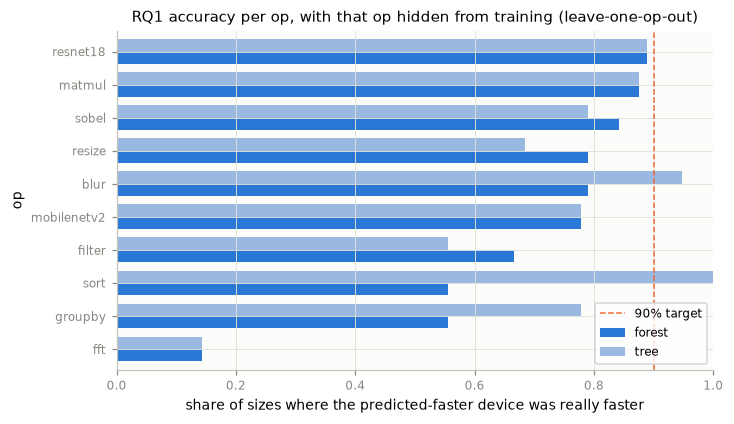

In [6]:
by_op = pd.read_csv(OUT / "rq1_by_op.csv").pivot(index="op", columns="model", values="accuracy").sort_values("forest")
ax = by_op.plot.barh(figsize=(7, 4), color=["#2a78d6", "#9ab9e0"], width=.75)
common.style(ax)
ax.axvline(.9, color=C["gpu"], ls="--", lw=1, label="90% target")
ax.set(xlabel="share of sizes where the predicted-faster device was really faster", xlim=(0, 1),
       title="RQ1 accuracy per op, with that op hidden from training (leave-one-op-out)")
ax.legend(loc="lower right", fontsize=8);

**Reading it:**
- On ops it has seen (5-fold) the forest is right **91%** of the time and wrong picks cost only **4%** extra
  time (regret) — target met.
- From the 30 s calibration alone it is right **81%** of the time with **6%** regret — good enough to start
  with, then it learns.
- On a never-seen op it drops to **69%**: the model doesn't generalise across kinds of work. The chart shows
  this case per op:
  - **fft is the worst (14%)**: having learned from the other ops that big inputs favour the GPU, it predicts
    the GPU — but on this card the CPU always wins fft (section 2).
  - **sort, groupby, filter (~56%)**: filter's mistakes are cheap (a near-tie), but wrong picks cost sort's
    forest 20% and groupby's forest 56% extra time.
  - **blur, sobel, matmul, the two networks (78–89%)** transfer well from the other ops.
- Time error (how far predicted seconds are from measured) is large (12–24% in-sample, ~90% unseen ops):
  the ranking is often right even when the absolute times are off.

## 4. RQ2 — does monitoring + switching beat fixed strategies under load?

`bench/experiments.py rq2` ran each workload with every strategy, alternating run by run, 1 warm-up + 5 timed
runs (warm-up excluded below), under four conditions:

- **idle** — plugged in, nothing else running
- **gpu** — a second process hammering the GPU with matrix multiplies
- **cpu** — busy loops on all 16 CPU threads (Python loops, since `stress-ng` doesn't exist on Windows)
- **battery** — charger out, Energy saver switched on by hand (a separate run, merged into
  `bench/results/*-rq2-all-conditions.csv`; see section 7 on how Windows reported Energy saver)

Summary, geometric means over workloads:

In [7]:
s = pd.read_csv(OUT / "rq2_summary.csv").set_index("condition")
s.style.format({"speedup_vs_gpu_geomean": "{:.2f}×", "speedup_vs_cpu_geomean": "{:.2f}×",
                "gap_to_oracle_geomean": "{:.0%}", "within_5pct_of_oracle": "{:.0%}", "switch_rate": "{:.0%}",
                "detect_ms_median": "{:.0f} ms", "autohetero_cv_median": "{:.0%}"})

,workloads,speedup_vs_gpu_geomean,speedup_vs_cpu_geomean,gap_to_oracle_geomean,within_5pct_of_oracle,switch_rate,detect_ms_median,autohetero_cv_median
condition,,,,,,,,
idle,18,0.76×,3.33×,41%,28%,10%,50 ms,9%
gpu,17,0.83×,2.27×,42%,41%,34%,74 ms,2%
cpu,16,0.25×,1.85×,306%,31%,19%,56 ms,16%
battery,17,0.71×,3.02×,50%,29%,20%,55 ms,31%


Per workload: green = AutoHetero faster than always-GPU, red = slower. The number is the speedup.

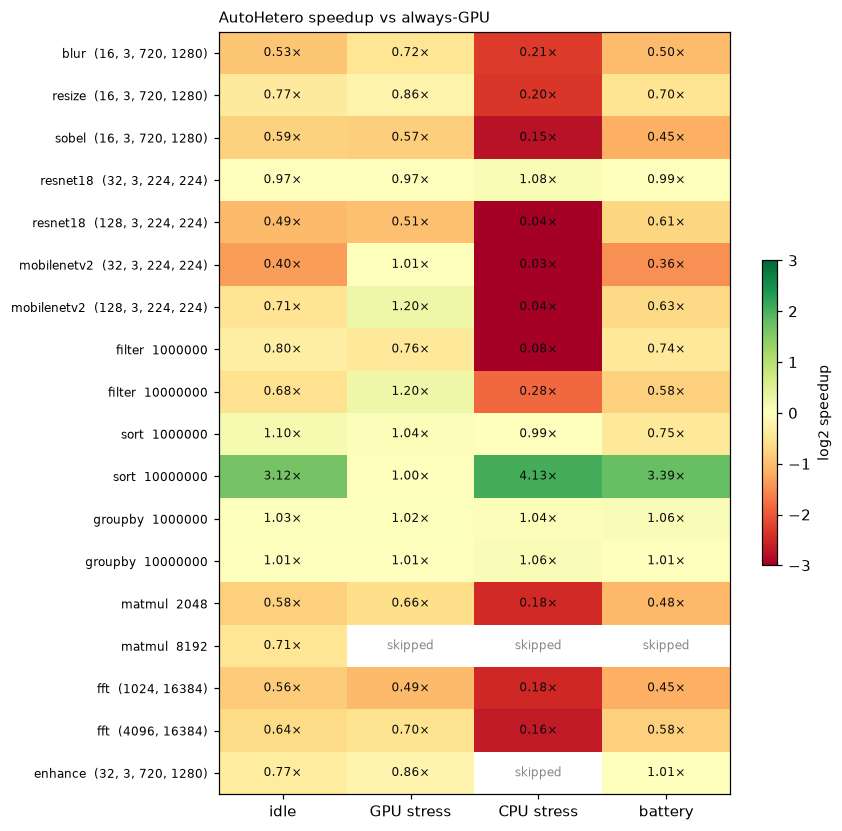

In [8]:
rq2 = pd.read_csv(OUT / "rq2.csv")
rq2["label"] = rq2["workload"] + "  " + rq2["size"].astype(str)
grid = rq2.pivot(index="label", columns="condition", values="speedup_vs_gpu")[["idle", "gpu", "cpu", "battery"]]
grid = grid.loc[rq2.drop_duplicates("label")["label"]]  # keep the experiment's workload order

fig, ax = plt.subplots(figsize=(7.5, 9))
im = ax.imshow(np.log2(grid.values.astype(float)), cmap="RdYlGn", vmin=-3, vmax=3, aspect="auto")
for (i, j), v in np.ndenumerate(grid.values):
    ax.text(j, i, "skipped" if np.isnan(v) else f"{v:.2f}×", ha="center", va="center", fontsize=8,
            color=common.MUTED if np.isnan(v) else common.INK)
ax.set_xticks(range(4), ["idle", "GPU stress", "CPU stress", "battery"])
ax.set_yticks(range(len(grid)), grid.index, fontsize=8)
ax.set_title("AutoHetero speedup vs always-GPU", loc="left")
fig.colorbar(im, ax=ax, shrink=.4, label="log2 speedup");

How the five strategies compare on each workload, idle and under each stress (milliseconds, median of 5;
bold = oracle):

In [9]:
cols = ["cpu_ms", "gpu_ms", "hybrid_ms", "autohetero_ms"]
for condition, g in rq2.groupby("condition", sort=False):
    t = g.set_index("label")[cols + ["autohetero_modes", "switch_rate"]]
    display(t.style.set_caption(f"condition: {condition}").format("{:.1f}", subset=cols, na_rep="—")
            .format("{:.0%}", subset=["switch_rate"])
            .highlight_min(subset=cols, axis=1, props="font-weight:bold; background-color:#e3f4ea"))

,cpu_ms,gpu_ms,hybrid_ms,autohetero_ms,autohetero_modes,switch_rate
label,,,,,,
"blur (16, 3, 720, 1280)",162.6,77.5,135.1,144.8,gpu,0%
"resize (16, 3, 720, 1280)",40.8,37.1,44.5,48.4,gpu,0%
"sobel (16, 3, 720, 1280)",268.9,67.8,138.2,115.2,gpu,0%
"resnet18 (32, 3, 224, 224)",715.8,55.9,231.3,57.4,gpu,0%
"resnet18 (128, 3, 224, 224)",2565.0,312.1,416.7,639.4,gpu,100%
"mobilenetv2 (32, 3, 224, 224)",474.3,59.9,164.9,151.3,hybrid,0%
"mobilenetv2 (128, 3, 224, 224)",1955.0,262.4,352.5,371.0,hybrid,0%
filter 1000000,6.4,6.6,7.9,8.3,gpu,0%
filter 10000000,58.9,55.4,50.4,80.9,gpu,0%


,cpu_ms,gpu_ms,hybrid_ms,autohetero_ms,autohetero_modes,switch_rate
label,,,,,,
"blur (16, 3, 720, 1280)",176.6,133.9,215.1,186.7,gpu,100%
"resize (16, 3, 720, 1280)",43.5,44.6,51.0,52.1,gpu,0%
"sobel (16, 3, 720, 1280)",262.1,99.5,157.9,174.5,gpu,80%
"resnet18 (32, 3, 224, 224)",734.8,112.8,136.7,116.0,gpu,0%
"resnet18 (128, 3, 224, 224)",2687.0,421.1,447.0,830.8,gpu,100%
"mobilenetv2 (32, 3, 224, 224)",474.4,124.2,132.8,123.4,hybrid,0%
"mobilenetv2 (128, 3, 224, 224)",1947.0,504.6,428.5,419.1,hybrid,0%
filter 1000000,6.7,11.7,13.1,15.4,gpu,0%
filter 10000000,61.9,104.7,74.7,87.1,gpu,100%


,cpu_ms,gpu_ms,hybrid_ms,autohetero_ms,autohetero_modes,switch_rate
label,,,,,,
"blur (16, 3, 720, 1280)",571.6,152.2,677.1,740.3,gpu hybrid,20%
"resize (16, 3, 720, 1280)",126.4,83.1,355.7,419.1,gpu,20%
"sobel (16, 3, 720, 1280)",379.1,72.0,521.9,482.2,gpu,60%
"resnet18 (32, 3, 224, 224)",5305.0,389.9,5059.0,361.6,gpu,0%
"resnet18 (128, 3, 224, 224)",8105.0,366.5,9393.0,8965.0,gpu,100%
"mobilenetv2 (32, 3, 224, 224)",11580.0,381.3,11450.0,11260.0,hybrid,0%
"mobilenetv2 (128, 3, 224, 224)",12630.0,485.2,11840.0,10880.0,hybrid,0%
filter 1000000,160.5,6.7,212.2,87.6,gpu,0%
filter 10000000,199.4,151.3,646.5,543.9,gpu hybrid,0%


,cpu_ms,gpu_ms,hybrid_ms,autohetero_ms,autohetero_modes,switch_rate
label,,,,,,
"blur (16, 3, 720, 1280)",172.8,79.2,143.9,159.5,gpu hybrid,0%
"resize (16, 3, 720, 1280)",48.1,38.3,48.4,54.5,gpu,0%
"sobel (16, 3, 720, 1280)",276.0,71.1,185.8,158.6,gpu,40%
"resnet18 (32, 3, 224, 224)",809.8,62.5,247.3,63.0,gpu,0%
"resnet18 (128, 3, 224, 224)",2897.0,422.2,462.9,690.6,gpu hybrid,60%
"mobilenetv2 (32, 3, 224, 224)",517.0,59.1,189.7,162.8,hybrid,0%
"mobilenetv2 (128, 3, 224, 224)",2072.0,278.7,453.5,444.0,hybrid,0%
filter 1000000,7.4,7.6,10.8,10.4,gpu,0%
filter 10000000,64.4,56.6,57.6,97.9,gpu hybrid,0%


**Reading it:**
- **AutoHetero always beats always-CPU** (3.3× idle, 2.3× GPU stress, 1.9× CPU stress, 3.0× battery) — it
  never makes the catastrophic "big neural net on the CPU" mistake.
- **But it is slower than plain always-GPU in every condition** (0.76×, 0.83×, 0.25×, 0.71×), and within 5%
  of the oracle on only 28–41% of workloads. The ≤ 5% hypothesis is not met on this machine.
- **Why slower even when it picks the GPU (idle):** the non-splittable ops (sort, groupby) run as one call
  and match always-GPU (~1.0×). The splittable ones (blur, sobel, matmul, resnet18…) run in ~10% chunks so a
  slowdown can be detected after each one (`executor.py`), and each chunk pays its own launch, copy and sync.
  A forced always-GPU run is one call. The chunking is the price of being able to react — and at idle there
  is nothing to react to.
- **GPU stress is where the idea works:** mobilenetv2 beats always-GPU (1.20×) by moving part of the batch to
  the free CPU, and switches fire in 34% of runs, detected in a median 74 ms.
- **CPU stress is where it goes wrong (0.25×):** with every CPU thread busy, chunk timings slow down, the
  slowdown check fires, and the rest of the call moves to *Hybrid — which puts work on the overloaded CPU*.
  resnet18 at batch 128 took 9.0 s instead of 0.37 s on the GPU. The likely root cause: the slowdown check
  sees "slower than predicted" but not *which* device is loaded, and the prediction for built-in ops ignores
  the CPU load (REQUIREMENTS, finding 3).
- **Battery looks like a slightly slower idle (0.71×):** compared with idle, the CPU ran 11% slower and the
  GPU 12% slower (geometric means over workloads), and AutoHetero 20% slower. Neither device lost enough
  speed to change which one wins, so the decisions — and the chunking cost — are the same as at idle.
- **sort at 10M (3.1× idle, 4.1× CPU stress, 3.4× battery) is not a real win** — it is an artifact of run
  order, confirmed in section 4b. Without it every RQ2 geomean vs always-GPU is lower.
- "skipped" cells were too big for the card's free memory under that condition — see section 7.

### 4b. Recheck: sort 10M and run order

Both AutoHetero and always-GPU ran sort 10M on the GPU, yet in RQ2 always-GPU took 220–535 ms against
AutoHetero's ~97 ms and the dataset's steady 91 ms. In RQ2 the forced GPU run always comes straight after a
3.4 s CPU sort (strategies alternate cpu → gpu → autohetero). A follow-up run at idle, plugged in, timed it in
three orders — 1 warm-up + 10 timed runs each:

| order | sequence | what follows the CPU sort |
|---|---|---|
| A | cpu → gpu → autohetero | always-GPU (the RQ2 order) |
| B | cpu → autohetero → gpu | AutoHetero |
| C | gpu only | nothing — no CPU sort at all |

sort10M-order-20261026-015912.csv · where the AutoHetero and always-GPU runs ran: ['gpu']


median     min     max
order strategy                          
A     autohetero    96.5    91.1    96.7
      cpu         3447.1  3434.5  3476.8
      gpu          266.5    96.4   403.0
B     autohetero   258.5   215.9   401.4
      cpu         3449.0  3431.1  3475.8
      gpu           96.6    96.3    97.2
C     gpu           90.8    90.6    91.2

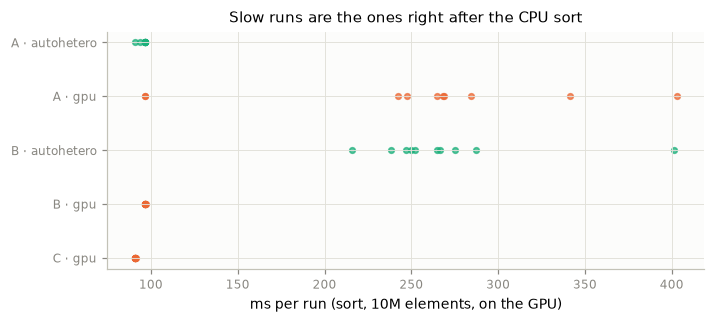

In [10]:
recheck = sorted((ROOT / "bench" / "results" / "recheck").glob("sort10M-order-*.csv"))[-1]
rc = pd.read_csv(recheck).query("rep > 0")
rc["ms"] = rc["seconds"] * 1e3
print(recheck.name, "· where the AutoHetero and always-GPU runs ran:", sorted(rc.query("strategy != 'cpu'")["mode"].unique()))
display(rc.groupby(["order", "strategy"])["ms"].agg(["median", "min", "max"]).round(1))

g = rc[rc["strategy"] != "cpu"]
fig, ax = plt.subplots(figsize=(7, 2.8))
common.style(ax)
labels = [f"{o} · {s}" for o, s in g.groupby(["order", "strategy"]).groups]
for y, ((o, s), runs) in enumerate(g.groupby(["order", "strategy"])["ms"]):
    ax.scatter(runs, [y] * len(runs), s=14, color=C[s], alpha=.7)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set(xlabel="ms per run (sort, 10M elements, on the GPU)", title="Slow runs are the ones right after the CPU sort")
ax.invert_yaxis();

In [11]:
geo = lambda x: float(np.exp(np.log(x).mean()))
clean = ~((rq2["workload"] == "sort") & (rq2["size"].astype(str) == "10000000"))
pd.DataFrame({
    "speedup vs GPU, as reported": rq2.groupby("condition", sort=False)["speedup_vs_gpu"].agg(geo),
    "without sort 10M": rq2[clean].groupby("condition", sort=False)["speedup_vs_gpu"].agg(geo),
    "within 5% of oracle, as reported": rq2.groupby("condition", sort=False)["gap_to_oracle"].agg(lambda g: (g <= .05).mean()),
    "without sort 10M ": rq2[clean].groupby("condition", sort=False)["gap_to_oracle"].agg(lambda g: (g <= .05).mean()),
}).style.format("{:.2f}×", subset=["speedup vs GPU, as reported", "without sort 10M"]).format("{:.0%}", subset=[
    "within 5% of oracle, as reported", "without sort 10M "])

,"speedup vs GPU, as reported",without sort 10M,"within 5% of oracle, as reported",without sort 10M
condition,,,,
idle,0.76×,0.70×,28%,24%
gpu,0.83×,0.82×,41%,38%
cpu,0.25×,0.21×,31%,27%
battery,0.71×,0.65×,29%,25%


**Reading it:** the slowdown follows the position, not the strategy. In order A always-GPU is slow
(median ~267 ms) and AutoHetero fast (~97 ms); swap them (order B) and it's AutoHetero that is slow (~259 ms)
while always-GPU is fast (~97 ms). With no CPU sort at all (C) the GPU sort takes ~91 ms. So on sort 10M,
AutoHetero and always-GPU are really about equal (~0.95–1.0×), and RQ2's 3–4× there is an artifact.

Why the run right after a long multi-threaded CPU op is slow isn't established here. One plausible cause is
CPU worker threads still spinning or the laptop's shared CPU–GPU power budget recovering for a few hundred ms.
The same effect may touch other workloads' always-GPU baselines in a smaller way (sort 1M shows ~10%); the
RQ2 design gives the forced GPU run no warm-up of its own after the CPU run, unlike `bench/collect.py`.

## 5. Hybrid gain — is splitting one call across both devices worth it?

On an idle machine, GPU-only vs forced Hybrid, for each splittable op across batch sizes. Gain = how much
faster Hybrid was (+10% = Hybrid 10% faster). The design hoped for 10–30%.

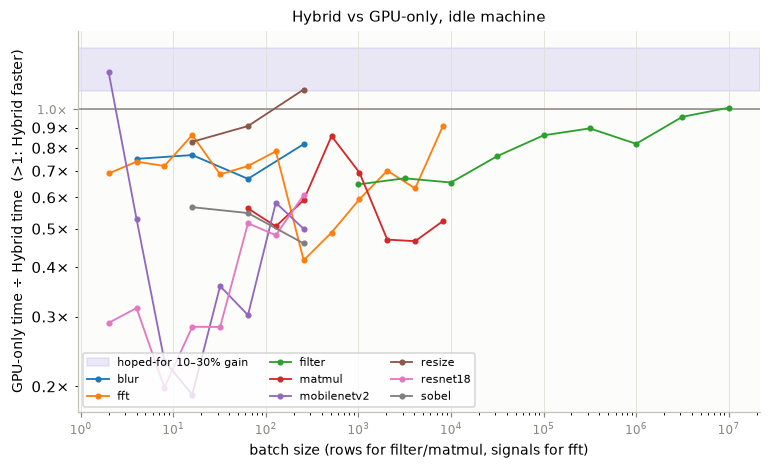

In [12]:
hg = pd.read_csv(OUT / "hybrid_gain.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
common.style(ax)
ax.axhline(1, color=common.MUTED, lw=1)
ax.axhspan(1 / .9, 1 / .7, color=C["hybrid"], alpha=.12, label="hoped-for 10–30% gain")
for op, g in hg.groupby("op"):
    ax.plot(g["batch"], g["gpu_ms"] / g["hybrid_ms"], "o-", ms=3, lw=1.2, label=op)
ax.set(xscale="log", yscale="log", xlabel="batch size (rows for filter/matmul, signals for fft)",
       ylabel="GPU-only time ÷ Hybrid time  (>1: Hybrid faster)", title="Hybrid vs GPU-only, idle machine")
times = plt.matplotlib.ticker.FormatStrFormatter("%.1f×")
ax.yaxis.set_major_formatter(times); ax.yaxis.set_minor_formatter(times)
ax.legend(fontsize=7, ncol=3, loc="lower left");

In [13]:
pd.read_csv(OUT / "hybrid_gain_summary.csv").set_index("op")

,gain_from_batch,max_gain,max_gain_batch
op,,,
blur,none,-0.223,256
fft,none,-0.100,8192
filter,10000000,0.010,10000000
matmul,none,-0.167,512
mobilenetv2,none,0.194,2
resize,256,0.110,256
resnet18,none,-0.644,256
sobel,none,-0.765,16


**Reading it:** Hybrid rarely pays on this laptop. It wins only on resize (+11% at batch 256), where the two
devices are about equally fast, and on mobilenetv2 at a tiny batch. Where the GPU is many times faster
(resnet18 −64%, sobel −77%), giving the CPU even a small share makes the GPU wait for it. A Ryzen 7 mobile CPU
is simply too far behind an RTX 3050 on most of these ops for splitting to help.

## 6. RQ3 — zero configuration and low overhead

What AutoHetero itself costs per call (tiny inputs, so only the dispatch is measured), against a direct call:

,value,unit
metric,,
"dispatch overhead: direct call, no AutoHetero (baseline)",0.14,us/call
dispatch overhead: @auto function,96.77,us/call
"dispatch overhead: @auto function, numpy input",136.30,us/call
dispatch overhead: @auto function inside force('cpu'),74.41,us/call
"dispatch overhead: built-in op, cached decision",157.90,us/call
dispatch overhead: decision miss (the forests run),26920.00,us/call
"calibration, once per machine",32.60,s
lines added to the demo app,1.00,lines


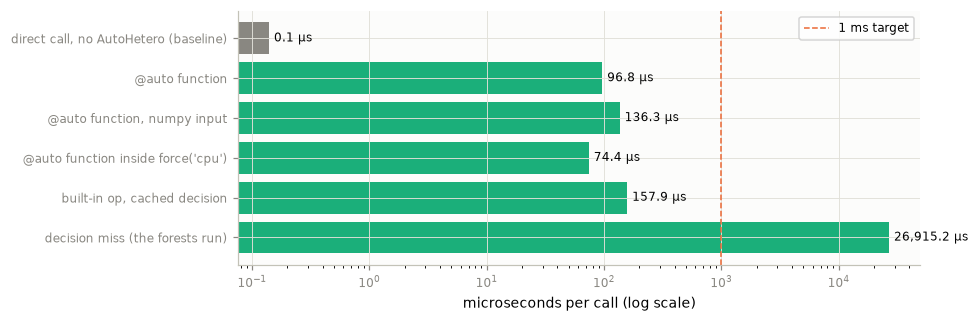

In [14]:
ov = pd.read_csv(OUT / "overhead.csv")
fig, ax = plt.subplots(figsize=(8, 3))
common.style(ax)
ax.barh(ov["case"], ov["microseconds_per_call"], color=[common.MUTED] + [C["autohetero"]] * (len(ov) - 1))
ax.axvline(1000, color=C["gpu"], ls="--", lw=1, label="1 ms target")
for y, v in enumerate(ov["microseconds_per_call"]):
    ax.text(v * 1.1, y, f"{v:,.1f} µs", va="center", fontsize=8)
ax.set(xscale="log", xlabel="microseconds per call (log scale)")
ax.invert_yaxis(); ax.legend(fontsize=8)
pd.read_csv(OUT / "rq3.csv").set_index("metric")

**Reading it:** a normal call costs ~0.1–0.16 ms, well under the 1 ms target. The 27 ms "decision miss" is
when the random forest actually runs; it happens once per new (op, size bucket, dtype, load bucket) and is then
cached, so it is a first-call cost, not a per-call one. Integration is one line in the demo app, and the only
setup a user waits through is the 33 s calibration. RQ3 is met.

## 7. Limits of this run — read before quoting numbers

In [15]:
from bench.experiments import WORKLOADS
ran = {(c, w, str(s)) for c, w, s in rq2[["condition", "workload", "size"]].itertuples(index=False)}
skipped = [(c, w, str(s)) for c in ["idle", "gpu", "cpu", "battery"] for w, s in WORKLOADS
           if (c, w, str(s)) not in ran]
print(f"{len(skipped)} rq2 workload runs skipped as too big for free GPU memory:")
pd.DataFrame(skipped, columns=["condition", "workload", "size"])

16 rq2 workload runs skipped as too big for free GPU memory:


,condition,workload,size
0,idle,blur,"(64, 3, 1080, 1920)"
1,idle,resize,"(64, 3, 1080, 1920)"
2,idle,sobel,"(64, 3, 1080, 1920)"
3,gpu,blur,"(64, 3, 1080, 1920)"
4,gpu,resize,"(64, 3, 1080, 1920)"
5,gpu,sobel,"(64, 3, 1080, 1920)"
6,gpu,matmul,8192
7,cpu,blur,"(64, 3, 1080, 1920)"
8,cpu,resize,"(64, 3, 1080, 1920)"
9,cpu,sobel,"(64, 3, 1080, 1920)"


In [16]:
fallbacks = raw["fallback"].astype(str).eq("True").sum()
print("runs where the GPU failed and the CPU stood in:", fallbacks, "(0 = every GPU number is a real GPU number)")

runs where the GPU failed and the CPU stood in: 0 (0 = every GPU number is a real GPU number)


- **4 GB card**: the 64×3×1080×1920 image workloads never fit; matmul 8192 doesn't fit next to the GPU
  stress job. matmul 8192 was also skipped under CPU stress and on battery, and `enhance` under CPU stress,
  though neither condition should hold GPU memory — unexplained.
- **Windows native, not WSL2** as the RUNBOOK specifies. The Windows NVIDIA driver spills oversized GPU work
  into system RAM instead of failing with out-of-memory; a GPU-memory check bug this hid (`calibrate.fits`)
  was fixed before these runs, and the fix is not committed yet.
- **CPU stress = Python busy loops**, not `stress-ng`.
- **Battery condition: Energy saver unconfirmed.** The run stayed on battery throughout (100% → 91%), and
  Energy saver was switched on by hand, but Windows' own status API (`PowerManager.EnergySaverStatus`)
  read Off before and after the run. The mild slowdown (section 4) is consistent with either.
- **sort 10M's always-GPU baseline is inflated by run order** (confirmed in section 4b): quote RQ2 without it.
- **Executor constants untuned** (`SLOWDOWN`, `FIRST_CHUNK`, …): first guesses, per the RUNBOOK's step 8.
- **Tests:** 43/44 GPU tests pass. The week-6 switch test is flaky here: at idle the predictor sometimes picks
  Hybrid instead of GPU for resnet18 batch 256, so the test's precondition fails; when it picks GPU, the
  switch under GPU stress happens within 2 chunks.

## 8. What this run says

| question | answer on this laptop |
|---|---|
| RQ1 — predict the faster device? | **Yes on known ops** (91%, 4% regret), 81% from calibration alone; **no on unseen ops** (69%) and fft |
| RQ2 — recover time by monitoring and rebalancing? | **Only under GPU contention**, and then barely. Without the sort 10M artifact, AutoHetero runs at 0.70× always-GPU idle, 0.82× under GPU stress, 0.65× on battery, and 0.21× under CPU stress, where switches move work *onto* the loaded CPU |
| Hybrid 10–30% gain? | **No**: one op gains 11%, most lose |
| RQ3 — zero config, < 1 ms? | **Yes**: ~0.1 ms/call, 1 line, 33 s one-off calibration |

The clearest improvement targets the data points to: make the slowdown check load-aware (don't move work onto a
busy CPU), skip chunking when the predicted gain from reacting is small, and fix fft's prediction.